# 6. Tabular transformer

Notebook 04 tried a transformer encoder over the six monthly timesteps (the `attention` row in its sequence study). This notebook tests the other kind: an **FT-Transformer**, where each engineered feature is a token and self-attention mixes them.

It reads exactly the features the deployed booster reads, so the only thing that differs is the model family. Like notebook 04 it feeds no decision; it answers "did you try transformers on the tabular features?".

The code is in `backend/app/ml/tabular_transformer.py`. Regenerate the results with:

    cd backend && python -m app.ml.tabular_transformer

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(PROJECT_ROOT / "backend"))

RESULTS = PROJECT_ROOT / "backend" / "artifacts" / "tabular_transformer.json"
if not RESULTS.exists():
    raise FileNotFoundError(
        f"{RESULTS} not found. Generate it with:\n"
        "    cd backend && python -m app.ml.tabular_transformer"
    )
results = json.loads(RESULTS.read_text(encoding="utf-8"))
print(f"features: {results['features']}  split seed: {results['split_seed']}  model seeds: {results['model_seeds']}")

features: 46  split seed: 42  model seeds: [42, 202, 777]


## 1. Configuration search

Four configurations, scored on validation AUC. The booster had seventy tuning configurations behind it, so one hand-set network would not be a fair test.

In [2]:
search = pd.DataFrame(results["search"]).sort_values("validation_auc", ascending=False)
search.round(4)

,token_size,layers,dropout,learning_rate,validation_auc,epochs
3,16,1,0.1,0.0030,0.7830,18
1,64,2,0.2,0.0005,0.7825,22
0,32,2,0.1,0.0010,0.7815,11
2,32,3,0.2,0.0003,0.7792,28


## 2. Head to head

The winner is refitted with three seeds and averaged. Test AUC is computed once, after every choice is made on validation.

In [3]:
table = pd.DataFrame({
    "validation AUC": {
        "logistic regression": results["logistic"]["validation_auc"],
        "FT-Transformer (3 seeds)": results["network"]["validation_auc"],
        "deployed booster": results["booster"]["validation_auc"],
    },
    "test AUC": {
        "logistic regression": results["logistic"]["test_auc"],
        "FT-Transformer (3 seeds)": results["network"]["test_auc"],
        "deployed booster": results["booster"]["test_auc"],
    },
})
table["test vs booster"] = table["test AUC"] - results["booster"]["test_auc"]
display(table.round(4))
pd.DataFrame(results["winner_seeds"]).round(4)

,validation AUC,test AUC,test vs booster
logistic regression,0.7626,0.7586,-0.0238
FT-Transformer (3 seeds),0.7840,0.7776,-0.0048
deployed booster,0.7832,0.7824,0.0000


,seed,validation_auc,epochs,test_auc
0,42,0.7830,18,0.7783
1,202,0.7819,13,0.7778
2,777,0.7834,11,0.7749


## 3. Does blending help?

The weight on the transformer is chosen on validation and applied once to test. The rank correlation says how much the two models disagree; a high value means little to gain from blending.

rank correlation with booster: 0.973
chosen weight: 0.6
validation: 0.7848 (+0.0017)
test:       0.7806 (-0.0019)


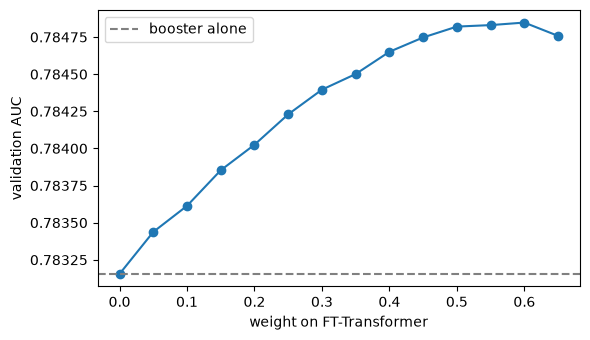

In [4]:
blend = results["blend"]
print(f"rank correlation with booster: {results['rank_correlation_with_booster']:.3f}")
print(f"chosen weight: {blend['weight']}")
print(f"validation: {blend['validation_auc']:.4f} ({blend['validation_gain']:+.4f})")
print(f"test:       {blend['test_auc']:.4f} ({blend['test_gain']:+.4f})")

sweep = pd.Series(results["blend_sweep_validation"])
sweep.index = sweep.index.astype(float)
ax = sweep.plot(marker="o", figsize=(6, 3.5))
ax.axhline(results["booster"]["validation_auc"], color="grey", linestyle="--", label="booster alone")
ax.set(xlabel="weight on FT-Transformer", ylabel="validation AUC")
ax.legend()
plt.tight_layout()

## Conclusion

**An FT-Transformer matches the booster but does not beat it.** Averaged over three seeds it scores 0.7840 on validation (booster 0.7832) and 0.7776 on test (booster 0.7824), a test gap of -0.005. Earlier work showed AUC moves by about ±0.01 across split seeds on this dataset, so this gap is inside the noise. It clearly beats logistic regression (0.7586 test), which is the same ceiling pattern seen throughout the project.

**Blending is selection bias again.** The weight chosen on validation (0.6) gains +0.0017 there and loses -0.0019 on test, the same reversal found in the sequence study of notebook 04. Neither the transformer nor a blend justifies replacing the served booster.

This closes the transformer question on both fronts: attention over the months (notebook 04, 0.758 validation) and attention over the engineered features (this notebook, 0.778 test). Neither passes the 0.78 ceiling.